# Figura 1: retrato de fase do pêndulo amortecido

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SEU-USUARIO/pendulo-caotico/blob/main/01_retrato_de_fase.ipynb)

Notebook de apoio ao artigo *Caracterização do caos no pêndulo forçado e amortecido: instabilidade, informação e geometria do espaço de fase*, **Seção III, Figura 1**.

O retrato de fase mostra o campo de velocidades do pêndulo amortecido **sem forçamento** ($f = 0$) no plano $(\theta, \omega)$ e marca os pontos de equilíbrio. Sem forçamento, toda trajetória perde energia e termina em um equilíbrio estável. É essa estrutura que o forçamento periódico perturba nas figuras seguintes.

**Tempo de execução:** cerca de 5 segundos.

## O modelo

Com $f = 0$, a Eq. (3) do artigo se reduz a

$$\dot\theta = \omega, \qquad \dot\omega = -q\,\omega - \sin\theta .$$

Nesta figura ilustrativa usa-se $q = 0{,}25$; nas demais figuras do artigo, $q = 0{,}5$. O amortecimento menor deixa mais visíveis as espirais em torno dos equilíbrios.

## Pontos de equilíbrio e estabilidade

Os equilíbrios satisfazem $\dot\theta = \dot\omega = 0$, isto é, $\omega = 0$ e $\sin\theta = 0$, logo $\theta^* = n\pi$ com $n$ inteiro. A estabilidade vem do jacobiano

$$J = \begin{pmatrix} 0 & 1 \\ -\cos\theta^* & -q \end{pmatrix},$$

cujos autovalores são as raízes de $\mu^2 + q\mu + \cos\theta^* = 0$:

$$\mu_\pm = \frac{-q \pm \sqrt{q^2 - 4\cos\theta^*}}{2}.$$

- **$n$ par** ($\cos\theta^* = 1$, pêndulo em repouso para baixo): $\mu_\pm = \tfrac{1}{2}\left(-q \pm \sqrt{q^2-4}\right)$. Para $q < 2$ os autovalores são complexos com parte real $-q/2 < 0$, e as trajetórias espiralam para o equilíbrio (foco estável).
- **$n$ ímpar** ($\cos\theta^* = -1$, pêndulo invertido): $\mu_\pm = \tfrac{1}{2}\left(-q \pm \sqrt{q^2+4}\right)$, um autovalor positivo e um negativo: ponto de sela.

## Código

### 1. Bibliotecas, estilo dos gráficos e pasta de figuras

In [1]:
# Dependências: numpy, matplotlib e numba.
# No Colab o Numba normalmente já vem instalado; se faltar, descomente a linha abaixo.
# !pip install numba

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Estilo dos gráficos
plt.rcParams.update({
    "figure.dpi": 140,
    "savefig.dpi": 300,
    "font.size": 12,
    "axes.titlesize": 13,
    "axes.labelsize": 12,
    "legend.fontsize": 10,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "mathtext.fontset": "stix",
    "font.family": "serif",
})

# Pasta onde as figuras são salvas
FIG_DIR = Path("figuras")
FIG_DIR.mkdir(exist_ok=True)

def savefig(name):
    path = FIG_DIR / f"{name}.png"
    plt.savefig(path, bbox_inches="tight")
    print(f"Figura salva em: {path}")

### 2. Parâmetros e malha

O campo é avaliado em uma malha de $80 \times 60$ pontos que cobre $\theta \in [-2\pi, 2\pi]$ e $\omega \in [-3{,}5;\ 3{,}5]$.

In [2]:
# Parâmetros do sistema (figura ilustrativa: q = 0,25 e sem forçamento)
q_phase = 0.25
theta_min, theta_max = -2*np.pi, 2*np.pi
omega_min, omega_max = -3.5, 3.5

# Malha (theta, omega) onde o campo de velocidades é calculado
theta_grid = np.linspace(theta_min, theta_max, 80)
omega_grid = np.linspace(omega_min, omega_max, 60)
TH, OM = np.meshgrid(theta_grid, omega_grid)

### 3. Campo de velocidades

Em cada ponto da malha, o vetor $(\dot\theta, \dot\omega)$ dá a direção em que o estado se move.

In [3]:
# Equações do pêndulo amortecido sem forçamento
DTH = OM                          # dθ/dt = ω
DOM = -np.sin(TH) - q_phase*OM    # dω/dt = -sen θ - q ω

### 4. Pontos de equilíbrio

Marcam-se os equilíbrios $\theta^* = n\pi$ para $n = -2, \dots, 2$: múltiplos pares de $\pi$ são estáveis, múltiplos ímpares são selas. A segunda célula confirma a classificação calculando numericamente os autovalores do jacobiano em cada ponto.

In [4]:
n_vals = np.arange(-2, 3)              # n = -2, -1, 0, 1, 2
theta_eq = n_vals * np.pi
omega_eq = np.zeros_like(theta_eq, dtype=float)

stable_mask = (n_vals % 2 == 0)        # múltiplos pares de π: estáveis
saddle_mask = ~stable_mask             # múltiplos ímpares de π: selas

In [5]:
# Verificação: autovalores de J = [[0, 1], [-cos θ*, -q]] em cada equilíbrio
for n, th in zip(n_vals, theta_eq):
    J = np.array([[0.0, 1.0], [-np.cos(th), -q_phase]])
    mu = np.linalg.eigvals(J)
    tipo = "estável (foco)" if np.all(mu.real < 0) else "sela"
    print(f"P_{n:+d}: θ* = {n:+d}π   autovalores: {mu[0]:.4f}, {mu[1]:.4f}   ->  {tipo}")

P_-2: θ* = -2π   autovalores: -0.1250+0.9922j, -0.1250-0.9922j   ->  estável (foco)
P_-1: θ* = -1π   autovalores: 0.8828, -1.1328   ->  sela
P_+0: θ* = +0π   autovalores: -0.1250+0.9922j, -0.1250-0.9922j   ->  estável (foco)
P_+1: θ* = +1π   autovalores: 0.8828, -1.1328   ->  sela
P_+2: θ* = +2π   autovalores: -0.1250+0.9922j, -0.1250-0.9922j   ->  estável (foco)


### 5. Figura

`streamplot` desenha as linhas de fluxo, curvas tangentes ao campo em todos os pontos. Círculos pretos marcam os equilíbrios estáveis ($P_0$, $P_{\pm 2}$) e quadrados vermelhos as selas ($P_{\pm 1}$).

Figura salva em: figuras/figura1_retrato_de_fase.png


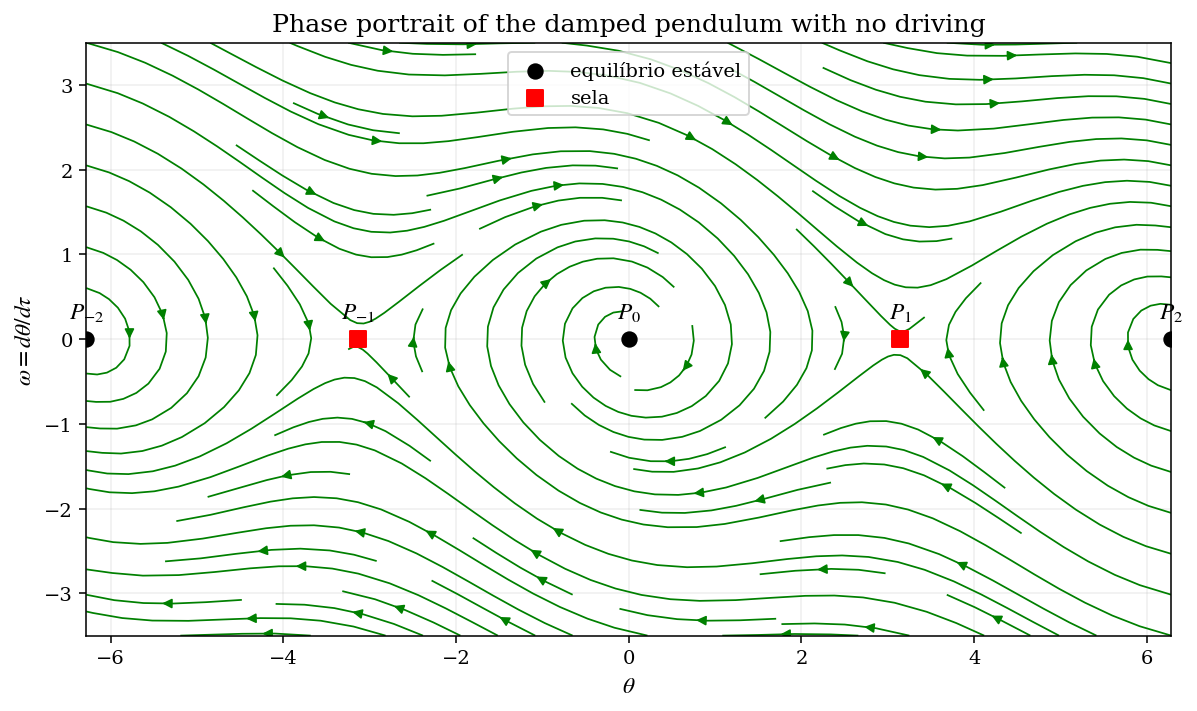

In [6]:
plt.figure(figsize=(10, 5.5))

# Linhas de fluxo
plt.streamplot(TH, OM, DTH, DOM, density=1.0, color="green", linewidth=0.9)

# Equilíbrios
plt.scatter(theta_eq[stable_mask], omega_eq[stable_mask],
            s=55, marker='o', color='black', label='equilíbrio estável', zorder=3)
plt.scatter(theta_eq[saddle_mask], omega_eq[saddle_mask],
            s=60, marker='s', color='red', label='sela', zorder=3)

# Rótulos P_n acima de cada equilíbrio
for n, xeq in zip(n_vals, theta_eq):
    plt.text(xeq, 0.25, fr'$P_{{{n}}}$', ha='center', fontsize=12)

plt.xlim(theta_min, theta_max)
plt.ylim(omega_min, omega_max)
plt.xlabel(r'$\theta$')
plt.ylabel(r'$\omega = d\theta/d\tau$')
plt.title('Phase portrait of the damped pendulum with no driving')
plt.grid(alpha=0.20)
plt.legend(frameon=True, loc='upper center')

savefig("figura1_retrato_de_fase")
plt.show()

## Leitura da figura

Em torno de cada equilíbrio estável as linhas de fluxo espiralam para dentro: o pêndulo oscila com amplitude decrescente até parar. As selas $P_{\pm 1}$ correspondem ao pêndulo invertido. As linhas que chegam exatamente às selas (suas variedades estáveis) separam as trajetórias que se acomodam em um poço daquelas que ainda passam por cima do ponto mais alto e mudam de poço. Essas curvas são as fronteiras entre as bacias de atração dos equilíbrios estáveis.

Com o forçamento ligado, essas fronteiras se deformam e se entrelaçam. Esse emaranhado está na origem da sensibilidade às condições iniciais estudada nos Notebooks 02 a 06.

## Para explorar

- Use `q_phase = 0` (sem atrito): as espirais viram órbitas fechadas em torno de $P_0$ e $P_{\pm 2}$.
- Use `q_phase = 2.5` ($q > 2$): os autovalores dos equilíbrios estáveis ficam reais e as espirais dão lugar a um nó.